# Analyze `optuna_search_lerm_kcpd.py` results (LERM + KernelCPD)

Optuna TPE search with patience-based early stopping for LERM (Fisher Information of a recurrence network) with **KernelCPD** as the transition
detector, run on CARC on the noisier data (60 train / 30 validation series; levels k1/k0p5/k0p25). Reads everything from `./results_lerm_kcpd/`.
Counterparts: the bootstrap-bound LERM search is `analyze_results.ipynb` (`./results/`), KS is `../optuna_search_kstest/analyze_results.ipynb`,
ruptures/KernelCPD on the raw signal is `../optuna_search/analyze_results.ipynb`.

- Outer search space (Optuna): `m`, `tau`, `target_density`, `w_size`, `w_incre_frac` (`w_incre = max(1, round(w_incre_frac * w_size))`). Inner sweep (8 cells, scored per trial, best cell kept): the
  KernelCPD penalty multiplier `k`, `pen = k * 8.3475 * log(n_FI) / log(6001)`. `block_size` is fixed at 2. The KernelCPD kernel/min_size are **not tuned** (linear kernel, min_size=20 raw samples, inherited from the raw-signal ruptures search).
- Sections: best config, convergence, hyperparameter-vs-score (with an edge-of-range check), inner sweep, train vs. validation, noise effect on the test split,
  **why is F1 low?** (comparison with the other detectors on the same data), and NGRIP.
- The TEST split was scored once, locally, with the frozen winner (`best_test_raw.csv`). If that file is missing, test columns are skipped.

In [1]:
import copy
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

METHODS_DIR = os.path.abspath("..")   # Methods/ -- for analyze_noise_effect.py
sys.path.insert(0, METHODS_DIR)
sys.path.insert(0, os.path.abspath("."))
from analyze_noise_effect import load_merged, summarize_all_splits, NOISIER_DATA_DIR
import optuna_search_lerm_kcpd as kc   # search-space constants + the exact pipeline functions

RES = "results_lerm_kcpd"
with open(os.path.join(RES, "best_params.json")) as f:
    best = json.load(f)
OBJ = best.get("objective", "warming")

trials_df = pd.read_csv(os.path.join(RES, "optuna_trials.csv"))
conv_df = pd.read_csv(os.path.join(RES, "optuna_convergence.csv"))
train_df = pd.read_csv(os.path.join(RES, "best_train_raw.csv"))
val_df = pd.read_csv(os.path.join(RES, "best_validation_raw.csv"))
surf_tr = pd.read_csv(os.path.join(RES, "best_inner_surface_train.csv"))
surf_va = pd.read_csv(os.path.join(RES, "best_inner_surface_validation.csv"))
test_csv = os.path.join(RES, "best_test_raw.csv")
test_df = pd.read_csv(test_csv) if os.path.exists(test_csv) else None
if test_df is None:
    print(f"{test_csv} not found -- test split not scored; test columns are skipped.")
complete = trials_df[trials_df["state"] == "COMPLETE"].sort_values("number")
print(f"objective optimized: f1_{OBJ}")
best

objective optimized: f1_warming


{'m': 5,
 'tau': 5,
 'target_density': 0.0114327262364086,
 'w_size': 16,
 'w_incre': 2,
 'w_incre_frac': 0.1290788363515874,
 'block_size': 2,
 'k': 0.35,
 'trial_number': 131,
 'objective': 'warming',
 'fixed': {'tau': 'shared across series (tuned)',
  'eps': 1,
  'density_tolerance': 0.002,
  'amp': 10,
  'kernelcpd': {'cost': 'linear',
   'beta_full': 8.34753880040116,
   'n_full': 6001,
   'pen_rule': 'k * beta_full * log(n_FI) / log(n_full)',
   'min_size_raw_samples': 20,
   'jump': 1}},
 'train_f1_all': 0.4064615915487449,
 'train_f1_warming': 0.3625740829789689,
 'train_f1_cooling': 0.35460535198641135,
 'train_mean_elapsed_s': 114.99841615778084,
 'run_metadata': {'wall_time_s': 44997.9060332072,
  'n_trials_this_run': 135,
  'n_trials_total': 135,
  'n_failed_total': 0,
  'patience': 50,
  'min_trials': 100,
  'min_delta': 0.01,
  'stopped_early': True,
  'stopped_at_trial': 134}}

## LERM + KernelCPD: best configuration

The winning `(m, target_density, w_size, w_incre)` plus the inner-sweep cell `(block_mult, block_size)` and how the search ended.

In [2]:
PARAM_NAMES = ["m", "tau", "target_density", "w_size", "w_incre", "k", "block_size"]
display(pd.Series({k: best.get(k) for k in PARAM_NAMES}, name="best value").to_frame())
print("fixed:", best.get("fixed"))
meta = best.get("run_metadata", {})
print(f"winning trial:      #{best['trial_number']}")
print(f"train f1_all / warming / cooling: {best['train_f1_all']:.3f} / {best['train_f1_warming']:.3f} / {best['train_f1_cooling']:.3f}")
print(f"mean time per series: {best['train_mean_elapsed_s']:.1f} s")
print(f"trials run: {meta.get('n_trials_total')}  (failed: {meta.get('n_failed_total')})  wall time: {meta.get('wall_time_s', float('nan'))/3600:.2f} h")
print(f"early stopping: patience={meta.get('patience')}, min_trials={meta.get('min_trials')}, min_delta={meta.get('min_delta')}, "
      f"stopped_early={meta.get('stopped_early')} (at trial {meta.get('stopped_at_trial')})")

,best value
m,5.000000
tau,5.000000
target_density,0.011433
w_size,16.000000
w_incre,2.000000
k,0.350000
block_size,2.000000


fixed: {'tau': 'shared across series (tuned)', 'eps': 1, 'density_tolerance': 0.002, 'amp': 10, 'kernelcpd': {'cost': 'linear', 'beta_full': 8.34753880040116, 'n_full': 6001, 'pen_rule': 'k * beta_full * log(n_FI) / log(n_full)', 'min_size_raw_samples': 20, 'jump': 1}}
winning trial:      #131
train f1_all / warming / cooling: 0.406 / 0.363 / 0.355
mean time per series: 115.0 s
trials run: 135  (failed: 0)  wall time: 12.50 h
early stopping: patience=50, min_trials=100, min_delta=0.01, stopped_early=True (at trial 134)


## LERM + KernelCPD: trial states and convergence

trials total: 135
state
COMPLETE    135
Name: count, dtype: int64


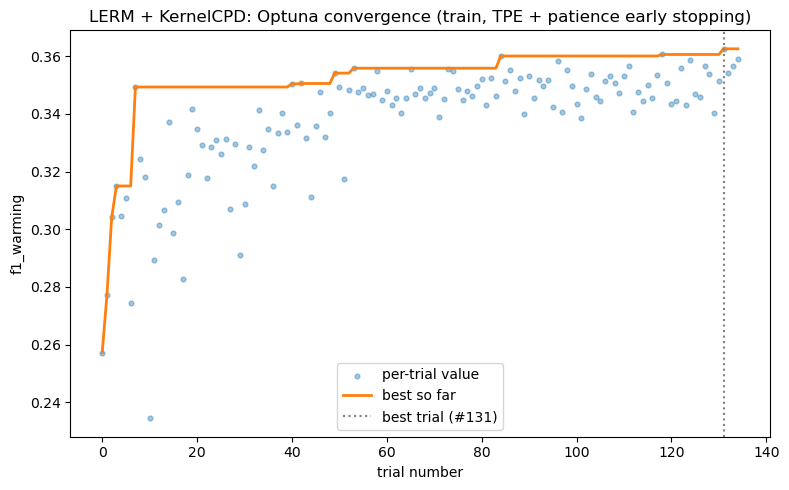

In [3]:
print(f"trials total: {len(trials_df)}")
print(trials_df["state"].value_counts())
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(complete["number"], complete["value"], s=12, alpha=0.4, label="per-trial value")
ax.plot(conv_df["number"], conv_df["best_value_so_far"], color="C1", linewidth=2, label="best so far")
ax.axvline(best["trial_number"], color="gray", linestyle=":", label=f"best trial (#{best['trial_number']})")
ax.set_xlabel("trial number"); ax.set_ylabel(f"f1_{OBJ}")
ax.set_title("LERM + KernelCPD: Optuna convergence (train, TPE + patience early stopping)")
ax.legend(); fig.tight_layout(); plt.show()

## LERM + KernelCPD: search space (train, every trial Optuna tried)

Each panel plots one hyperparameter against the trial's train `f1_warming`; color = trial number. The dashed line marks the winning value, dotted lines the search bounds.

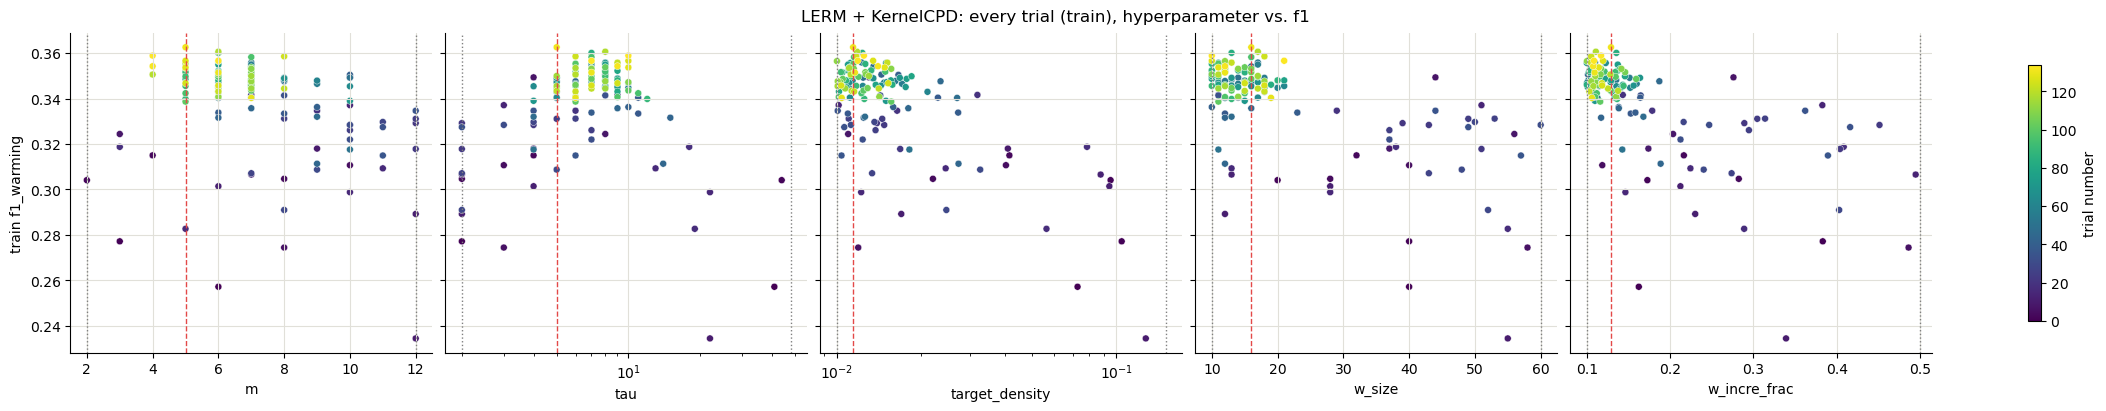

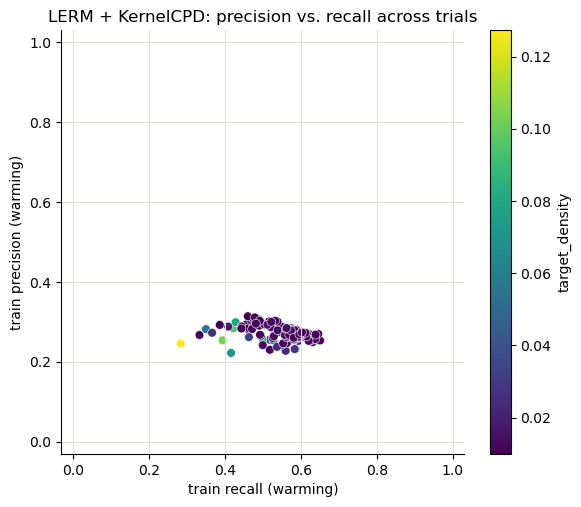

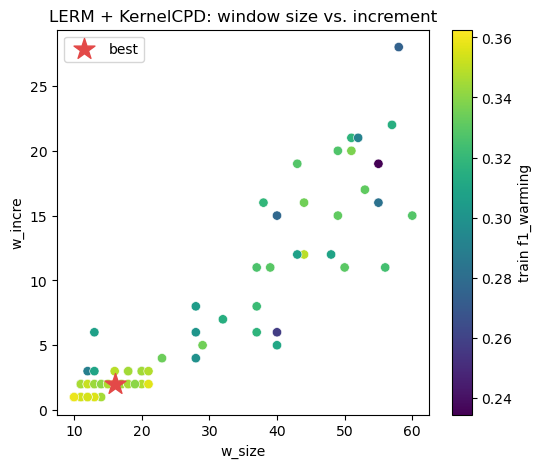

Top 10 trials:


,number,value,params_m,params_target_density,params_tau,params_w_size,user_attrs_w_incre,user_attrs_best_k,user_attrs_mean_n_detected,user_attrs_mean_elapsed_s
131,131,0.362574,5,0.011433,5,16,2,0.35,84.116667,114.998416
118,118,0.360606,6,0.011808,8,17,2,0.25,87.350000,118.594256
84,84,0.360080,6,0.012338,7,13,2,0.10,118.083333,112.764406
134,134,0.358889,4,0.012494,10,10,1,0.50,84.666667,108.936099
124,124,0.358541,8,0.011739,6,18,2,0.10,115.083333,126.158453
96,96,0.358239,7,0.011520,7,16,2,0.15,102.750000,114.908587
133,133,0.356622,6,0.011879,7,21,2,0.15,107.700000,112.030911
127,127,0.356616,5,0.013482,10,10,1,0.25,102.366667,109.666790
111,111,0.356469,6,0.010009,7,12,1,0.25,109.066667,115.745289
53,53,0.355849,7,0.012273,8,17,2,0.10,112.566667,107.758206


In [4]:
BOUNDS = {"m": kc.M_BOUNDS, "tau": kc.TAU_BOUNDS, "target_density": kc.TARGET_DENSITY_BOUNDS, "w_size": kc.W_SIZE_BOUNDS, "w_incre_frac": kc.W_INCRE_FRAC_BOUNDS}
fig, axes = plt.subplots(1, 5, figsize=(21, 4), sharey=True, constrained_layout=True)
for ax, name in zip(axes, BOUNDS):
    sc = ax.scatter(complete[f"params_{name}"], complete["value"], c=complete["number"], cmap="viridis", s=25, edgecolor="white", linewidth=0.3)
    ax.axvline(best[name], color="#e34948", linestyle="--", linewidth=1)
    for b in BOUNDS[name]:
        ax.axvline(b, color="gray", linestyle=":", linewidth=1)
    ax.set_xlabel(name)
    if name in ("target_density", "tau"):
        ax.set_xscale("log")
    ax.grid(color="#e1e0d9", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel(f"train f1_{OBJ}")
fig.colorbar(sc, ax=axes.tolist(), label="trial number", shrink=0.8)
fig.suptitle("LERM + KernelCPD: every trial (train), hyperparameter vs. f1")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(complete[f"user_attrs_mean_recall_{OBJ}"], complete[f"user_attrs_mean_precision_{OBJ}"],
                c=complete["params_target_density"], cmap="viridis", s=40, edgecolor="white", linewidth=0.4)
ax.set_xlabel(f"train recall ({OBJ})"); ax.set_ylabel(f"train precision ({OBJ})")
ax.set_xlim(-0.03, 1.03); ax.set_ylim(-0.03, 1.03)
ax.grid(color="#e1e0d9", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(sc, label="target_density"); ax.set_title("LERM + KernelCPD: precision vs. recall across trials")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
sc = ax.scatter(complete["params_w_size"], complete["user_attrs_w_incre"], c=complete["value"], cmap="viridis", s=45, edgecolor="white", linewidth=0.4)
ax.scatter(best["w_size"], best["w_incre"], marker="*", s=250, color="#e34948", label="best")
ax.set_xlabel("w_size"); ax.set_ylabel("w_incre"); ax.legend()
fig.colorbar(sc, label=f"train f1_{OBJ}"); ax.set_title("LERM + KernelCPD: window size vs. increment")
plt.show()

print("Top 10 trials:")
cols = ["number", "value", "params_m", "params_target_density", "params_tau", "params_w_size",
        "user_attrs_w_incre", "user_attrs_best_k", "user_attrs_mean_n_detected", "user_attrs_mean_elapsed_s"]
display(complete.nlargest(10, "value")[cols])

### Did the search pile up at the edge of its ranges?

When the best trials sit on a bound, the optimizer is asking for more of the same than the range allows, so the bound (not the optimizer) limits the score.
The first LERM search (bootstrap bounds) also piled up at its edges, which is why these ranges were widened.

In [5]:
top = complete.nlargest(10, "value")
rows = []
for name, (lo, hi) in BOUNDS.items():
    col = top[f"params_{name}"]
    rel = 1e-6 if name == "target_density" else 0
    at_lo = int((col <= lo * (1 + 0.15) if name == "target_density" else col <= lo).sum())
    at_hi = int((col >= hi).sum())
    rows.append(dict(param=name, lower=lo, upper=hi, winner=best[name], top10_at_lower=at_lo, top10_at_upper=at_hi,
                     top10_min=col.min(), top10_max=col.max()))
display(pd.DataFrame(rows).set_index("param").round(4))
print("(target_density 'at lower' = within 15% of the lower bound; the other bounds are checked exactly.)")
print(f"best k of the top-10 winners: {top['user_attrs_best_k'].value_counts().sort_index().to_dict()}")

,lower,upper,winner,top10_at_lower,top10_at_upper,top10_min,top10_max
param,,,,,,,
m,2.00,12.00,5.0000,0,0,4.0000,8.0000
tau,2.00,48.00,5.0000,0,0,5.0000,10.0000
target_density,0.01,0.15,0.0114,2,0,0.0100,0.0135
w_size,10.00,60.00,16.0000,2,0,10.0000,21.0000
w_incre_frac,0.10,0.50,0.1291,0,0,0.1002,0.1355


(target_density 'at lower' = within 15% of the lower bound; the other bounds are checked exactly.)
best k of the top-10 winners: {0.1: 3, 0.15: 2, 0.25: 3, 0.35: 1, 0.5: 1}


## LERM + KernelCPD: inner sweep (`k`) at the winning outer config

Each trial scores 8 penalty multipliers `k` on the same FI series and keeps the best; this shows all 8 for the winning trial (series-mean). If the cells are nearly equal, the penalty is not what limits the score.

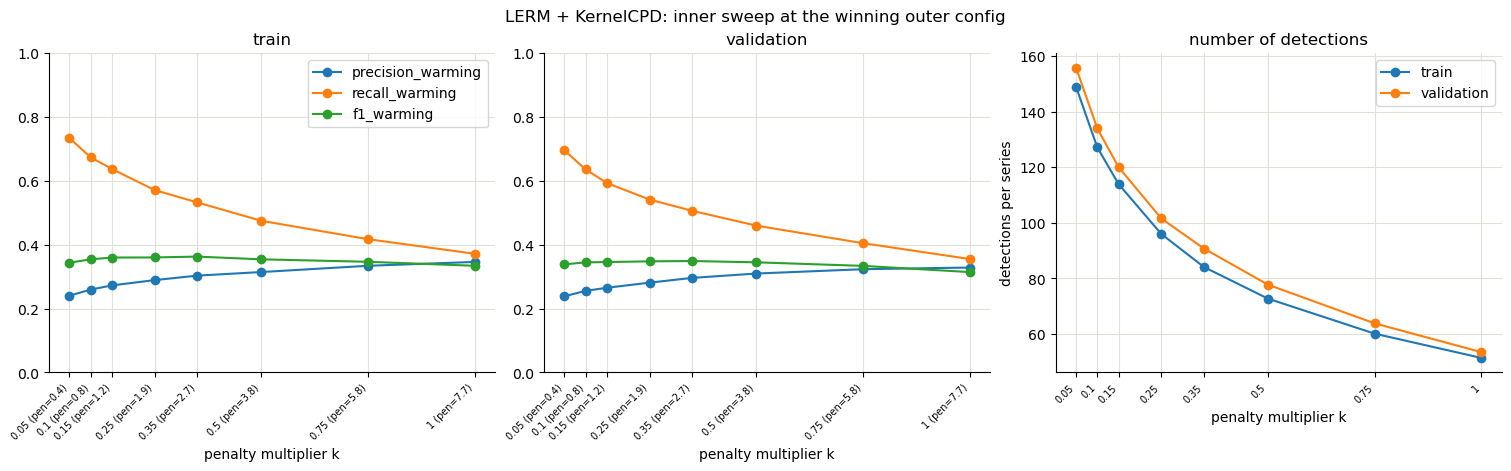

k    pen    n_fi  n_detected  false_positives_all  \
train      0  0.05  0.384  2981.0     148.983              110.883   
           1  0.10  0.768  2981.0     127.100               92.100   
           2  0.15  1.151  2981.0     113.900               80.817   
           3  0.25  1.919  2981.0      95.983               66.083   
           4  0.35  2.687  2981.0      84.117               56.217   
           5  0.50  3.838  2981.0      72.750               47.600   
           6  0.75  5.757  2981.0      60.167               38.000   
           7  1.00  7.676  2981.0      51.450               31.567   
validation 0  0.05  0.384  2981.0     155.833              114.333   
           1  0.10  0.768  2981.0     133.933               95.467   
           2  0.15  1.151  2981.0     120.000               83.967   
           3  0.25  1.919  2981.0     101.567               68.600   
           4  0.35  2.687  2981.0      90.767               60.367   
           5  0.50  3.838  2981.0      77.767               50.233   
           6  0.75  5.757  2981.0      63.867               40.000   
           7  1.00  7.676  2981.0      53.533               32.667   

              precision_all  recall_all  f1_all  timing_mae_all  \
train      0          0.264       0.815   0.379           0.246   
           1          0.286       0.751   0.392           0.245   
           2          0.301       0.711   0.399           0.243   
           3          0.321       0.646   0.402           0.239   
           4          0.339       0.604   0.406           0.235   
           5          0.353       0.544   0.400           0.229   
           6          0.379       0.488   0.397           0.227   
           7          0.397       0.439   0.388           0.225   
validation 0          0.270       0.819   0.388           0.243   
           1          0.290       0.757   0.399           0.243   
           2          0.302       0.708   0.402           0.241   
           3          0.327       0.653   0.410           0.233   
           4          0.338       0.607   0.407           0.232   
           5          0.354       0.555   0.404           0.233   
           6          0.373       0.488   0.394           0.229   
           7          0.389       0.433   0.381           0.228   

              timing_n_matched_all  precision_warming  recall_warming  \
train      0                38.100              0.240           0.734   
           1                35.000              0.259           0.674   
           2                33.083              0.272           0.637   
           3                29.900              0.289           0.571   
           4                27.900              0.303           0.532   
           5                25.150              0.314           0.475   
           6                22.167              0.334           0.417   
           7                19.883              0.346           0.372   
validation 0                41.500              0.238           0.695   
           1                38.467              0.255           0.636   
           2                36.033              0.265           0.593   
           3                32.967              0.281           0.541   
           4                30.400              0.296           0.506   
           5                27.533              0.310           0.460   
           6                23.867              0.323           0.405   
           7                20.867              0.328           0.355   

              f1_warming  timing_mae_warming  timing_n_matched_warming  \
train      0       0.343               0.226                    16.933   
           1       0.354               0.227                    15.550   
           2       0.360               0.226                    14.667   
           3       0.360               0.226                    13.083   
           4       0.363               0.224                    12.100   


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
for ax, (name, df) in zip(axes[:2], [("train", surf_tr), ("validation", surf_va)]):
    for m in ("precision", "recall", "f1"):
        ax.plot(df["k"], df[f"{m}_{OBJ}"], marker="o", label=f"{m}_{OBJ}")
    ax.set_xlabel("penalty multiplier k"); ax.set_title(name); ax.set_ylim(0, 1)
    ax.set_xticks(df["k"]); ax.set_xticklabels([f"{c:g} (pen={p:.1f})" for c, p in zip(df["k"], df["pen"])], rotation=45, ha="right"); ax.tick_params(axis="x", labelsize=7)
    ax.grid(color="#e1e0d9", linewidth=0.8); ax.spines[["top", "right"]].set_visible(False)
axes[0].legend()
for name, df in [("train", surf_tr), ("validation", surf_va)]:
    axes[2].plot(df["k"], df["n_detected"], marker="o", label=name)
axes[2].set_xticks(surf_tr["k"]); axes[2].set_xticklabels([f"{c:g}" for c in surf_tr["k"]], rotation=45, ha="right"); axes[2].tick_params(axis="x", labelsize=7)
axes[2].set_xlabel("penalty multiplier k"); axes[2].set_ylabel("detections per series"); axes[2].set_title("number of detections")
axes[2].legend(); axes[2].grid(color="#e1e0d9", linewidth=0.8); axes[2].spines[["top", "right"]].set_visible(False)
fig.suptitle("LERM + KernelCPD: inner sweep at the winning outer config")
plt.show()
display(pd.concat({"train": surf_tr, "validation": surf_va}).round(3))

## LERM + KernelCPD: winning config, train vs. validation vs. test

Per-series breakdown for the single winning config, split by direction (`all` / `warming` / `cooling`).

In [7]:
metric_cols = [c for c in train_df.columns if c.startswith(("precision_", "recall_", "f1_"))]
summary = {"train_mean": train_df[metric_cols].mean(), "val_mean": val_df[metric_cols].mean()}
if test_df is not None:
    summary["test_mean"] = test_df[metric_cols].mean()
display(pd.DataFrame(summary).round(3))
print(f"train -> validation drop in f1_{OBJ}: {train_df[f'f1_{OBJ}'].mean() - val_df[f'f1_{OBJ}'].mean():+.3f}")

,train_mean,val_mean,test_mean
precision_all,0.339,0.338,0.361
recall_all,0.604,0.607,0.623
f1_all,0.406,0.407,0.445
precision_warming,0.303,0.296,0.313
recall_warming,0.532,0.506,0.510
f1_warming,0.363,0.349,0.376
precision_cooling,0.298,0.302,0.320
recall_cooling,0.523,0.545,0.564
f1_cooling,0.355,0.366,0.398


train -> validation drop in f1_warming: +0.014


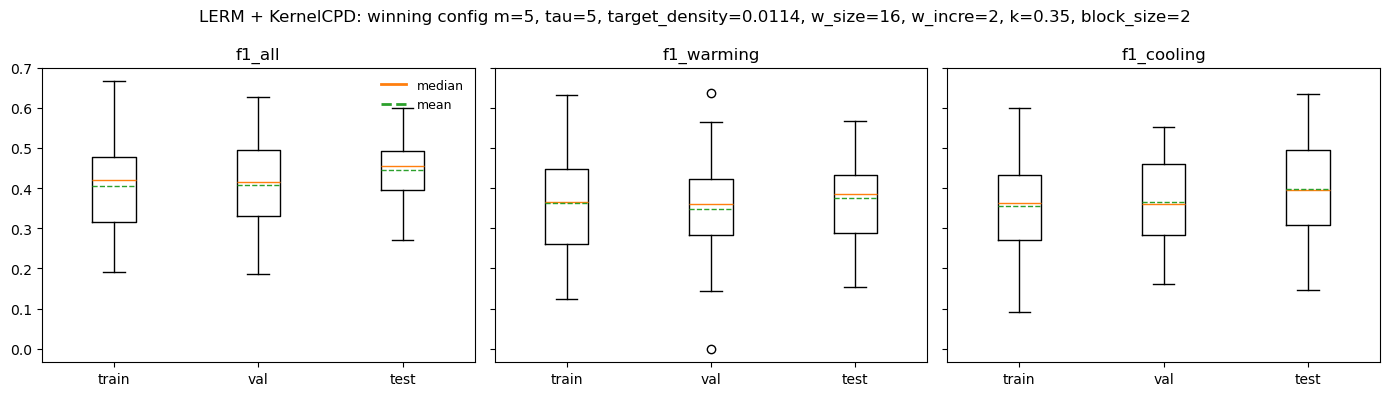

In [8]:
splits = [("train", train_df), ("val", val_df)] + ([("test", test_df)] if test_df is not None else [])
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, label in zip(axes, ("all", "warming", "cooling")):
    ax.boxplot([df[f"f1_{label}"].dropna() for _, df in splits], tick_labels=[n for n, _ in splits], showmeans=True, meanline=True)
    ax.set_title(f"f1_{label}")
axes[0].legend(handles=[Line2D([0], [0], color="C1", linewidth=2, label="median"),
                        Line2D([0], [0], color="C2", linewidth=2, linestyle="--", label="mean")], loc="upper right", frameon=False, fontsize=9)
fig.suptitle("LERM + KernelCPD: winning config " + ", ".join(f"{k}={best[k]:.3g}" for k in PARAM_NAMES))
fig.tight_layout(); plt.show()

## LERM + KernelCPD: noise-condition effect (TEST split, winning config)

How noise **color** (white/pink/red) and **level** (SNR) change detection performance, as in the KS notebook: the frozen winning config scored once on the held-out **test** split
(`best_test_raw.csv`, scored locally with `evaluate_final_test`, no CARC job needed). Tables show train / validation / test side by side; the figures use the test split only.
Level k = SNR: sigma_noise = gap / k, so k1 is the cleanest and k0p25 the noisiest. Rows of `best_*_raw.csv` are matched to the manifests in `noisier_data/train_test_split_data/` by position.

In [9]:
MERGED = {s: load_merged(RES, NOISIER_DATA_DIR, s) for s in ("train", "validation", "test")}
METRICS = [f"precision_{OBJ}", f"recall_{OBJ}", f"f1_{OBJ}"]
for metric in METRICS:
    print(f"=== LERM + KernelCPD: {metric} by noise condition -- train vs validation vs test (sorted by train mean) ===")
    print(summarize_all_splits(MERGED, metric).to_string(float_format=lambda x: f"{x:.3f}"))
    print()

=== LERM + KernelCPD: precision_warming by noise condition -- train vs validation vs test (sorted by train mean) ===
            train             validation              test            
             mean   std count       mean   std count  mean   std count
color level                                                           
red   k1    0.442 0.158     7      0.427 0.154     3 0.446 0.060     4
      k0p5  0.409 0.080     7      0.434 0.164     3 0.436 0.033     3
white k1    0.347 0.077     6      0.339 0.108     3 0.303 0.069     4
pink  k1    0.323 0.068     7      0.312 0.183     3 0.333 0.080     3
red   k0p25 0.322 0.154     6      0.266 0.156     4 0.402 0.101     3
pink  k0p25 0.252 0.114     7      0.243 0.106     3 0.209 0.063     4
white k0p25 0.213 0.097     6      0.213 0.100     5 0.181 0.061     3
pink  k0p5  0.210 0.070     7      0.263 0.243     3 0.255 0.044     3
white k0p5  0.203 0.080     7      0.233 0.091     3 0.241 0.024     3

=== LERM + KernelCPD: recall_w

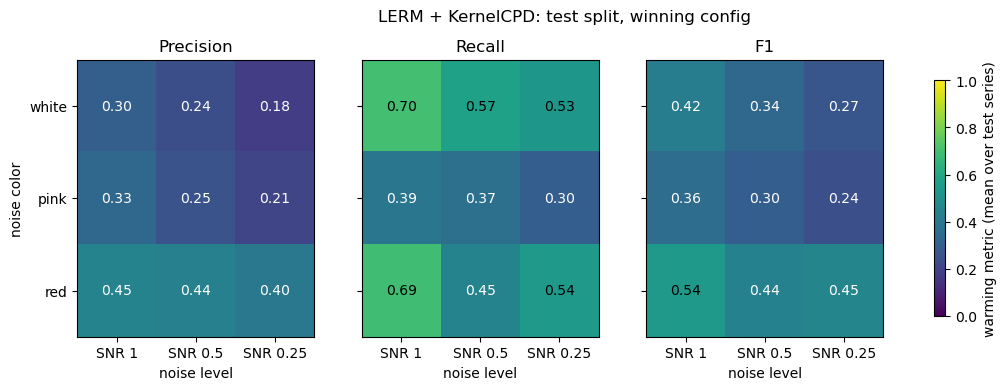

In [10]:
if MERGED["test"] is None:
    print("test split not scored (best_test_raw.csv missing) -- skipped")
else:
    # Precision, recall and F1 side by side (TEST split, winning config), shared 0-1 colour scale -- same figure as the KS notebook.
    _ORDER_LEVELS = ["k1", "k0p5", "k0p25"]            # clean -> noisy
    _ORDER_COLORS = ["white", "pink", "red"]
    _LEVEL_LABELS = {"k1": "SNR 1", "k0p5": "SNR 0.5", "k0p25": "SNR 0.25"}
    _titles = {"precision": "Precision", "recall": "Recall", "f1": "F1"}
    _test = MERGED["test"]

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
    for ax, key in zip(axes, ["precision", "recall", "f1"]):
        pv = _test.pivot_table(index="color", columns="level", values=f"{key}_{OBJ}", aggfunc="mean").reindex(index=_ORDER_COLORS, columns=_ORDER_LEVELS)
        im = ax.imshow(pv.values, cmap="viridis", vmin=0, vmax=1, aspect="auto")
        ax.set_xticks(range(len(_ORDER_LEVELS))); ax.set_xticklabels([_LEVEL_LABELS[l] for l in _ORDER_LEVELS])
        ax.set_yticks(range(len(_ORDER_COLORS))); ax.set_yticklabels(_ORDER_COLORS)
        ax.set_title(_titles[key]); ax.set_xlabel("noise level")
        for i in range(pv.shape[0]):
            for j in range(pv.shape[1]):
                v = pv.values[i, j]
                if pd.notna(v):
                    ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < 0.5 else "black")
    axes[0].set_ylabel("noise color")
    fig.suptitle("LERM + KernelCPD: test split, winning config", y=1.02)
    fig.colorbar(im, ax=axes.tolist(), shrink=0.85, label=f"{OBJ} metric (mean over test series)")
    plt.show()


=== LERM + KernelCPD, test: mean f1_warming vs SNR ===
  snr  mean   sem  count
0.250 0.314 0.036     10
0.500 0.359 0.024      9
1.000 0.445 0.028     11


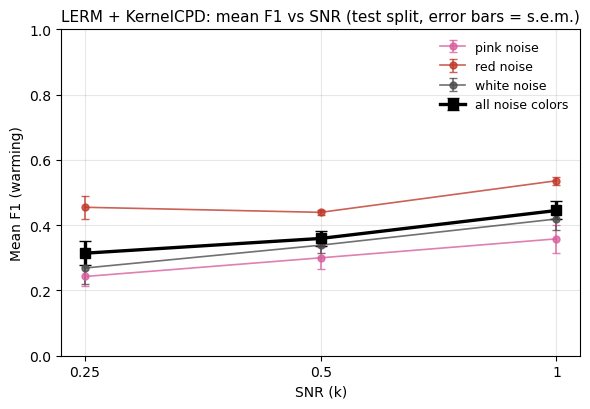

In [11]:
if MERGED["test"] is None:
    print("test split not scored (best_test_raw.csv missing) -- skipped")
else:
    # Mean F1 vs SNR (test split, winning config), one line per noise color plus the overall mean.
    SNR_OF_LEVEL = {"k1": 1.0, "k0p5": 0.5, "k0p25": 0.25}
    COLORS = {"white": "#4d4d4d", "pink": "#d95f9e", "red": "#c0392b"}
    metric = f"f1_{OBJ}"
    df = MERGED["test"].assign(snr=lambda d: d["level"].map(SNR_OF_LEVEL))
    by_color = df.groupby(["color", "snr"])[metric].agg(["mean", "sem"]).reset_index()
    overall = df.groupby("snr")[metric].agg(["mean", "sem", "count"]).reset_index()
    print(f"=== LERM + KernelCPD, test: mean {metric} vs SNR ===")
    print(overall.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

    fig, ax = plt.subplots(figsize=(6, 4.2))
    for color, g in by_color.groupby("color"):
        ax.errorbar(g["snr"], g["mean"], yerr=g["sem"], marker="o", ms=5, lw=1.2, capsize=3, alpha=0.8, color=COLORS.get(color), label=f"{color} noise")
    ax.errorbar(overall["snr"], overall["mean"], yerr=overall["sem"], marker="s", ms=7, lw=2.4, capsize=4, color="black", label="all noise colors")
    ax.set_xscale("log"); ticks = sorted(SNR_OF_LEVEL.values())
    ax.set_xticks(ticks); ax.set_xticklabels([f"{v:g}" for v in ticks]); ax.minorticks_off()
    ax.set_ylim(0, 1); ax.set_xlabel("SNR (k)"); ax.set_ylabel(f"Mean F1 ({OBJ})")
    ax.set_title("LERM + KernelCPD: mean F1 vs SNR (test split, error bars = s.e.m.)", fontsize=11)
    ax.grid(alpha=0.3); ax.legend(frameon=False, fontsize=9); fig.tight_layout()
    plt.show()


## LERM + KernelCPD: why is F1 low?

Same noisier data, same scoring. The other rows use the same train/validation series, so the comparison is detector/representation only:

- **KernelCPD on the raw signal** (`../optuna_search/results`): the settings that LERM+KernelCPD inherits.
- **KS on the raw signal** (`../optuna_search_kstest/noisier_results`).
- **LERM with bootstrap bounds** (`./results`, the first LERM search).

If LERM+KernelCPD is below KernelCPD-on-raw, the FI transformation is losing information relative to the raw series (the detector is identical).

In [12]:
def _load(d, split):
    f = os.path.join(d, f"best_{split}_raw.csv")
    return pd.read_csv(f) if os.path.exists(f) else None
DIRS = {
    "LERM + KernelCPD": RES,
    "LERM + bootstrap bounds": "results",
    "KernelCPD on raw": os.path.join(METHODS_DIR, "optuna_search", "results"),
    "KS on raw": os.path.join(METHODS_DIR, "optuna_search_kstest", "noisier_results"),
}
cols = ["precision_warming", "recall_warming", "f1_warming", "precision_all", "recall_all", "f1_all", "timing_mae_warming"]
rows = {}
for name, d in DIRS.items():
    for split in ("train", "validation", "test"):
        df = _load(d, split)
        if df is not None:
            rows[f"{name} ({split})"] = df[cols].mean()
table = pd.DataFrame(rows).T
display(table.round(3))

,precision_warming,recall_warming,f1_warming,precision_all,recall_all,f1_all,timing_mae_warming
LERM + KernelCPD (train),0.303,0.532,0.363,0.339,0.604,0.406,0.224
LERM + KernelCPD (validation),0.296,0.506,0.349,0.338,0.607,0.407,0.226
LERM + KernelCPD (test),0.313,0.510,0.376,0.361,0.623,0.445,0.215
LERM + bootstrap bounds (train),0.303,0.231,0.245,0.414,0.307,0.327,0.235
LERM + bootstrap bounds (validation),0.309,0.222,0.242,0.403,0.293,0.318,0.289
LERM + bootstrap bounds (test),0.306,0.229,0.255,0.411,0.290,0.329,0.232
KernelCPD on raw (train),0.570,0.643,0.569,0.595,0.659,0.588,0.169
KernelCPD on raw (validation),0.575,0.565,0.532,0.598,0.591,0.552,0.188
KernelCPD on raw (test),0.565,0.600,0.564,0.604,0.635,0.598,0.179
KS on raw (train),0.484,0.606,0.430,0.501,0.632,0.449,0.157


In [13]:
d = np.load(os.path.join(NOISIER_DATA_DIR, "train.npz"))
n_true = np.mean([(np.diff(x) != 0).sum() for x in d["state_true"]])
print(f"true transitions per train series: {n_true:.1f}  |  LERM+KernelCPD detections per series: {train_df['n_detected'].mean():.1f}  "
      f"|  matched (all): {train_df['timing_n_matched_all'].mean():.1f}  |  false positives: {train_df['false_positives_all'].mean():.1f}")
print(f"timing MAE of matched warming events: {train_df['timing_mae_warming'].mean():.2f} kyr (tolerance {kc.TOLERANCE})")

true transitions per train series: 48.2  |  LERM+KernelCPD detections per series: 84.1  |  matched (all): 27.9  |  false positives: 56.2
timing MAE of matched warming events: 0.22 kyr (tolerance 0.5)


In [14]:
# Does F1 depend on how many events the series has? (manifest of the noisier train split)
man = pd.read_csv(os.path.join(NOISIER_DATA_DIR, "train_manifest.csv"))
byev = pd.concat([train_df[[f"f1_{OBJ}", f"precision_{OBJ}", f"recall_{OBJ}"]].reset_index(drop=True), man[["source"]]], axis=1)
display(byev.groupby("source").mean().round(3).assign(n=byev.groupby("source").size()))

,f1_warming,precision_warming,recall_warming,n
source,,,,
15event,0.301,0.209,0.610,20
25event,0.372,0.295,0.542,20
40event,0.415,0.405,0.445,20


## Direction convention and NGRIP

NGRIP's time axis is **age** (kyr b2k), which runs backwards. The synthetic series run forward in time, and the direction classifier (`_classify_detected_directions`)
calls a detection *warming* when the signal's mean increases through the array. So NGRIP must be reversed into forward time (time = -age) before detection, as in
the KS notebook. Skipping this swaps warming and cooling: on the raw age axis, the signal *drops* through the array at 22 of the 25 real DO warming onsets (checked below).

In [15]:
import ammonyte as amt
from ammonyte.utils.metrics import evaluate_detection

AMMONYTE_DATA_DIR = os.path.join(os.path.dirname(amt.__file__), "data")
ngrip_series = amt.Series.from_csv(os.path.join(AMMONYTE_DATA_DIR, "NGRIP.csv"))
do_df = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "DO_onsets_Rasmussen2014.csv"), comment="#")   # 25 main GI onsets (Rasmussen 2014)
do_gt_age = np.sort(do_df["main25_kyr_b2k"].dropna().values.astype(float))

# sanity check of the sign convention: change of the signal through the array at each real warming onset
t_age = np.asarray(ngrip_series.time, float); v_age = np.asarray(ngrip_series.value, float)
delta = [v_age[i:i + 10].mean() - v_age[max(0, i - 10):i].mean() for i in (int(np.argmin(abs(t_age - e))) for e in do_gt_age)]
print(f"age axis (as stored): signal change through the array at the {len(do_gt_age)} warming onsets -> "
      f"{int(np.sum(np.array(delta) < 0))} negative, {int(np.sum(np.array(delta) > 0))} positive")

def to_forward_time(series):
    return amt.Series(time=-series.time[::-1], value=series.value[::-1], time_name="time (forward)", time_unit="-kyr b2k",
                      value_name=series.value_name, value_unit=series.value_unit, label=f"{series.label} (forward time)", verbose=False)

ngrip_win = to_forward_time(ngrip_series.slice([do_gt_age.min(), do_gt_age.max()]))
ngrip_std = ngrip_win.standardize()
do_gt_times = np.sort(-do_gt_age)
print(f"NGRIP window: {len(ngrip_std.time)} points; DO events: {len(do_gt_age)}")

Time axis values sorted in ascending order
Time axis values sorted in ascending order
age axis (as stored): signal change through the array at the 25 warming onsets -> 25 negative, 0 positive
NGRIP window: 5034 points; DO events: 25


## LERM + KernelCPD applied to real NGRIP data

The frozen winning config (zero re-tuning) on the NGRIP record in forward time, standardized like the synthetic series. Only **warming**-classified detections inside the labeled range are scored against the 25 real DO warming events (Rasmussen 2014). All-detections scoring is also shown for reference (it counts cooling detections as false positives, since the catalog lists warming only).

In [16]:
def score_ngrip(series, gt_times, params, tolerance=kc.TOLERANCE, label=""):
    t = np.asarray(series.time, float); v = np.asarray(series.value, float)
    fi = kc._fisher_series(t, v, int(params["m"]), int(params["tau"]), params["target_density"], int(params["w_size"]), int(params["w_incre"]))
    smoothed = amt.utils.fisher.smooth_series(copy.deepcopy(fi), block_size=int(params["block_size"]))
    fi_std = kc._standardized_fi(smoothed)
    det_all, _ = kc._detect_kcpd(fi_std, float(np.median(np.diff(t))), params["k"])
    dirs_all = kc._classify_detected_directions(v, t, det_all)
    in_range = (det_all >= gt_times.min()) & (det_all <= gt_times.max())
    det, dirs = det_all[in_range], dirs_all[in_range]
    warming = det[dirs == "warming"]
    print(f"--- {label}: {len(det_all)} detected, {len(det)} in range, {len(warming)} warming (scored) ---")
    m_w = evaluate_detection(detected=warming, ground_truth=gt_times, tolerance=tolerance)
    m_a = evaluate_detection(detected=det, ground_truth=gt_times, tolerance=tolerance)
    print("warming only:", m_w); print("all in range:", m_a)
    return warming, det, m_w, m_a

ngrip_det, ngrip_all, ngrip_m, ngrip_m_all = score_ngrip(ngrip_std, do_gt_times, best, label="LERM + KernelCPD, standardized NGRIP")

--- LERM + KernelCPD, standardized NGRIP: 67 detected, 67 in range, 42 warming (scored) ---
warming only: Detection Evaluation Metrics
Metrics calculated within tolerance = 0.5

Performance Scores:
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| Precision |  0.4762 |
+-----------+---------+
| Recall    |  0.8    |
+-----------+---------+
| F1 Score  |  0.597  |
+-----------+---------+

Detection Counts:
+-----------------+---------+
| Category        |   Count |
+=================+=========+
| True Positives  |      20 |
+-----------------+---------+
| False Positives |      22 |
+-----------------+---------+
| False Negatives |       5 |
+-----------------+---------+

Summary:
  Detected: 42 | Ground Truth: 25

all in range: Detection Evaluation Metrics
Metrics calculated within tolerance = 0.5

Performance Scores:
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| Precision |  0.3134 |
+-----------+---------+
| Recall    |  0.84   |
+-

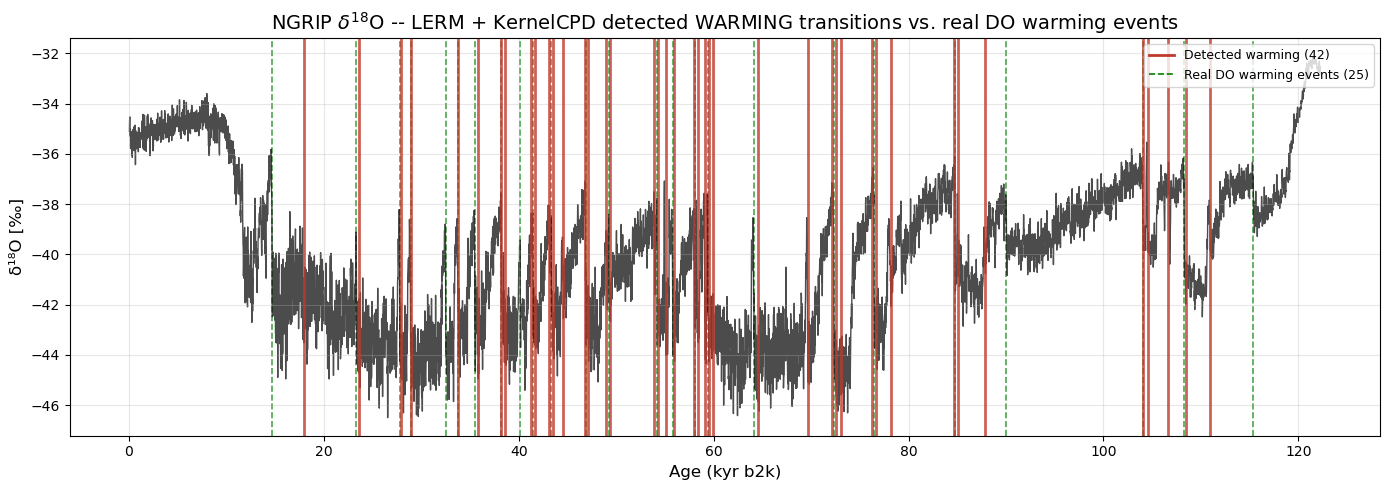

In [17]:
from ammonyte.core.transitions import DeterministicTransitions

# computed in forward time, drawn on the original NGRIP age axis (age = -time_fwd)
def to_age_axis(fwd_times, label):
    ages = np.sort(-np.asarray(fwd_times, float))
    return DeterministicTransitions(series=ngrip_series, jump_times=ages, jump_values=np.ones(len(ages)),
                                    method="LERM + KernelCPD", method_args=dict(best), label=label)

age_transitions = to_age_axis(ngrip_det, "LERM + KernelCPD warming (age axis)")
fig, ax = age_transitions.plot(
    figsize=(14, 5), show_transitions="all", transition_color="#c0392b",
    legend_labels=[f"Detected warming ({len(ngrip_det)})"],
    title="NGRIP $\\delta^{18}$O -- LERM + KernelCPD detected WARMING transitions vs. real DO warming events",
)
for t in do_gt_age:
    ax.axvline(t, color="green", linestyle="--", linewidth=1.2, alpha=0.7, zorder=0)
ax.plot([], [], color="green", linestyle="--", linewidth=1.2, label=f"Real DO warming events ({len(do_gt_age)})")
ax.set_xlabel("Age (kyr b2k)")
ax.legend(loc="upper right", fontsize=9)
plt.show()


In [18]:
def _means(df):
    return [df["precision_warming"].mean(), df["recall_warming"].mean(), df["f1_warming"].mean()]
comparison = pd.DataFrame({
    "LERM+KCPD train": _means(train_df), "LERM+KCPD validation": _means(val_df),
    "LERM+KCPD test": _means(test_df) if test_df is not None else [np.nan] * 3,
    "LERM+KCPD NGRIP (standardized)": [ngrip_m.precision, ngrip_m.recall, ngrip_m.f1_score],
}, index=["precision_warming", "recall_warming", "f1_warming"]).dropna(axis=1, how="all")
comparison

,LERM+KCPD train,LERM+KCPD validation,LERM+KCPD test,LERM+KCPD NGRIP (standardized)
precision_warming,0.303044,0.295969,0.312503,0.476190
recall_warming,0.532239,0.505843,0.510274,0.800000
f1_warming,0.362574,0.348702,0.375666,0.597015
